# Supplementary Figure S7. RUBRIC scores across experimental methods

In [1]:
import json
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import Normalize

def _root() -> Path:
    here = Path.cwd().resolve()
    for base in [here, *here.parents]:
        if (base / "data").is_dir() and (base / "notebooks").is_dir():
            return base
    raise RuntimeError("run this from inside the analysis repo")

ROOT = _root()
data_file = lambda rel: ROOT / "data" / rel
_json = lambda rel: json.loads(data_file(rel).read_text())

def save(fig, rel):
    path = ROOT / rel
    path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(path)
    return path

plt.rcParams.update({
    "figure.dpi": 130, "savefig.dpi": 600, "savefig.bbox": "tight",
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica Neue", "Helvetica", "DejaVu Sans"],
    "font.size": 8.5, "axes.labelsize": 9, "axes.titlesize": 9,
    "xtick.labelsize": 8, "ytick.labelsize": 8, "legend.fontsize": 8,
    "axes.linewidth": 0.8, "xtick.major.width": 0.8, "ytick.major.width": 0.8,
    "xtick.direction": "out", "ytick.direction": "out",
    "axes.grid": False, "legend.frameon": False,
    "pdf.fonttype": 42, "ps.fonttype": 42,
})
BLUE, ORANGE, GREEN, RED, GREY = "#4C72B0", "#DD8452", "#55A868", "#C44E52", "0.55"
POINT_FACE, POINT_EDGE, FIT = "#C9C9C9", "0.15", "#111111"

CUT = 80.0

LW = ["cWW", "tWW", "cWH", "tWH", "cWS", "tWS", "cHH", "tHH", "cHS", "tHS", "cSS", "tSS"]
TOOLS = ["rubric", "fr3d", "rnaview", "barnaba", "rnapolis", "bpnet"]
TOOL_LABELS = ["RUBRIC", "FR3D", "RNAView", "barnaba", "RNApolis", "BPNet"]

def finish(ax):
    for side in ("top", "right", "bottom", "left"):
        ax.spines[side].set_visible(True)
        ax.spines[side].set_linewidth(0.8)
    ax.grid(False)
    ax.tick_params(direction="out", width=0.8, length=3.5)
    return ax

def letter(fig, ax, s, dx=-0.030, dy=0.012):
    box = ax.get_position()
    fig.text(box.x0 + dx, box.y1 + dy, s, fontsize=13, fontweight="bold",
             ha="left", va="bottom")

def pair_scores() -> pd.DataFrame:
    return pd.read_json(data_file("reference/scores/pair_scores_uniques_rubric.jsonl"), lines=True)

def scored_pairs(lw_only=True) -> pd.DataFrame:
    df = pair_scores()
    df = df[~df["is_ambiguous"].fillna(False) & df["score"].notna()].copy()
    return df[df["lw_class"].isin(LW)].copy() if lw_only else df

def _resolution(m):
    if not isinstance(m, dict):
        return None
    return (m.get("EM Diffraction Resolution (Å)") or m.get("Refinement_resolution")
            or m.get("EM Resolution (Å)"))

def structure_scores() -> pd.DataFrame:
    sc = _json("reference/scores/scores_all_uniques.json")["scores"]
    md = _json("reference/metadata/metadata_cache.json")
    vm, nt = md["validation_metrics"], md["nucleotide_counts"]
    rows = []
    for pdb, info in sc.items():
        m = vm.get(pdb) if isinstance(vm.get(pdb), dict) else {}
        rows.append({"pdb": pdb, "pairs_score": info.get("pairs_score"),
                     "backbone_suiteness": info.get("backbone_suiteness"),
                     "n_pairs": info.get("n_pairs", 0),
                     "n_residues_scored": info.get("n_residues_scored", 0),
                     "method": m.get("Experimental_method"),
                     "resolution": _resolution(m), "clashscore": m.get("clashscore"),
                     "rnasuiteness": m.get("rnasuiteness"),
                     "n_nucleotides": nt.get(pdb),
                     "deposited": m.get("Deposition_Date")})
    return pd.DataFrame(rows)

def runtime() -> pd.DataFrame:
    df = pd.read_csv(data_file("benchmark/dssr_RUBRIC_time_benchmark.csv"))
    df = df[(df["Nucleotides"] > 0) & (df["dssr_avg"] > 0) & (df["rubric_avg"] > 0)].copy()
    df["ratio"] = df["dssr_avg"] / df["rubric_avg"]
    return df

WEIGHTS = _json("reference/scoring_tables/penalty_weights.json")["penalty_weights"]
ISSUES = list(WEIGHTS)
ISSUE_LABELS = {"distance": "H-bond distance", "hbond_angles": "H-bond angles",
                "incorrect_hbond_count": "H-bond count", "stretch": "Stretch",
                "opening": "Opening", "stagger": "Stagger", "propeller": "Propeller",
                "shear": "Shear", "buckle": "Buckle", "clash": "Clash"}

def hist_grid(fig, spec, df, params, xlabel, cols=3):
    rows = int(np.ceil(len(params) / cols))
    sub = spec.subgridspec(rows, cols, wspace=0.42, hspace=0.62)
    axes = []
    for i, p in enumerate(params):
        ax = fig.add_subplot(sub[i // cols, i % cols])
        vals = pd.to_numeric(df[p], errors="coerce").dropna()
        if len(vals) > 20000:
            vals = vals.sample(20000, random_state=1)
        ax.hist(vals, bins=40, color=BLUE, alpha=0.8)
        ax.set_xlabel(p.replace("_", " "), fontsize=7.5)
        ax.tick_params(labelsize=6.5)
        if i % cols == 0:
            ax.set_ylabel("Count", fontsize=7.5)
        finish(ax)
        axes.append(ax)
    return axes

AXIS_LABEL_PT = 8.5


def enlarge_axis_labels(fig, text_pt=7.0, axis_pt=AXIS_LABEL_PT):
    for ax in fig.axes:
        for lab in (ax.xaxis.label, ax.yaxis.label):
            if lab.get_text().strip():
                lab.set_fontsize(lab.get_fontsize() * axis_pt / text_pt)


## Panel setup
Structure-level table


In [2]:
MIN_PAIRS = 1                                   # every structure with a scored pair
STRUCT = structure_scores()
_N_SCORED = pair_scores().dropna(subset=["score"]).groupby("pdb_id").size()
STRUCT["n_scored"] = STRUCT["pdb"].map(_N_SCORED).fillna(0).astype(int)
STRUCT = STRUCT[(STRUCT.n_scored >= MIN_PAIRS) & STRUCT.pairs_score.notna()].copy()
print(f"{len(STRUCT):,} scored structures | {STRUCT.resolution.notna().sum():,} with resolution")
NMR_STRUCT = pd.DataFrame([{"pdb": pdb, "pairs_score": s["pairs_score"],
                            "backbone_suiteness": s["backbone_suiteness"],
                            "n_scored": s["n_scored"], "method": "NMR"}
                           for pdb, s in _json("reference/scores/scores_nmr_nonredundant.json")["scores"].items()])
NMR_STRUCT = NMR_STRUCT[(NMR_STRUCT.n_scored >= MIN_PAIRS) & NMR_STRUCT.pairs_score.notna()].copy()
print(f"{len(NMR_STRUCT):,} scored NMR structures (non-redundant, model 1)")

METHODS = (("X-ray", BLUE, "X-ray"), ("EM", ORANGE, "cryo-EM"), ("NMR", GREY, "NMR"))
SIZE_BINS = ((MIN_PAIRS, 100, "≤100"), (101, 999, "101-999"), (1000, np.inf, "≥1,000"))
YLIM = {"pairs_score": (50, 101), "backbone_suiteness": (-0.03, 1.0)}

def method_groups(col):
    """{(size label, method label): values} for one structure-level column."""
    df = pd.concat([STRUCT, NMR_STRUCT]).dropna(subset=["method", col])
    out = {}
    for lo, hi, size in SIZE_BINS:
        in_bin = df[(df.n_scored >= lo) & (df.n_scored <= hi)]
        for method, _, label in METHODS:
            v = in_bin.loc[in_bin.method.astype(str).str.contains(method, case=False, na=False), col].to_numpy()
            if len(v) >= 5:
                out[(size, label)] = v
    return out

def method_row(axes, col, ylabel):
    """One small panel per structure-size bin (scored pairs); violins per method, shared y."""
    groups = method_groups(col)
    for i, (ax, (_, _, size)) in enumerate(zip(axes, SIZE_BINS)):
        present = [(color, label, groups[(size, label)]) for _, color, label in METHODS
                   if (size, label) in groups]
        xs = [k + (len(METHODS) - len(present)) / 2 for k in range(len(present))]   # centred
        for x, (color, _, v) in zip(xs, present):
            vp = ax.violinplot([v], positions=[x], widths=0.8, showextrema=False, bw_method=0.2)
            for body in vp["bodies"]:
                body.set_facecolor(color); body.set_edgecolor(color); body.set_alpha(0.75)
            q1, med, q3 = np.percentile(v, [25, 50, 75])
            ax.vlines(x, q1, q3, color="black", lw=1.6)
            ax.scatter([x], [med], s=10, color="white", edgecolor="black", lw=0.7, zorder=3)
        ax.set_xlim(-0.6, len(METHODS) - 0.4)
        ax.set_xticks(xs, [label for _, label, _ in present])
        ax.set_ylim(*YLIM[col])
        ax.set_title(f"{size} pairs")
        if i == 0:
            ax.set_ylabel(ylabel)
        else:
            ax.tick_params(labelleft=False)
        finish(ax)

for col in ("pairs_score", "backbone_suiteness"):
    print(col, {f"{s} {m}": (len(v), round(float(np.median(v)), 2)) for (s, m), v in method_groups(col).items()})


1,965 scored structures | 1,965 with resolution
561 scored NMR structures (non-redundant, model 1)
pairs_score {'≤100 X-ray': (993, 98.92), '≤100 cryo-EM': (430, 97.07), '≤100 NMR': (561, 97.39), '101-999 X-ray': (65, 96.87), '101-999 cryo-EM': (127, 97.58), '≥1,000 X-ray': (59, 96.2), '≥1,000 cryo-EM': (291, 98.17)}
backbone_suiteness {'≤100 X-ray': (992, 0.56), '≤100 cryo-EM': (430, 0.46), '≤100 NMR': (560, 0.42), '101-999 X-ray': (65, 0.56), '101-999 cryo-EM': (127, 0.47), '≥1,000 X-ray': (59, 0.48), '≥1,000 cryo-EM': (291, 0.51)}


## Panel A
Base-pair quality-score distributions for X-ray, cryo-EM and NMR structures, by structure size


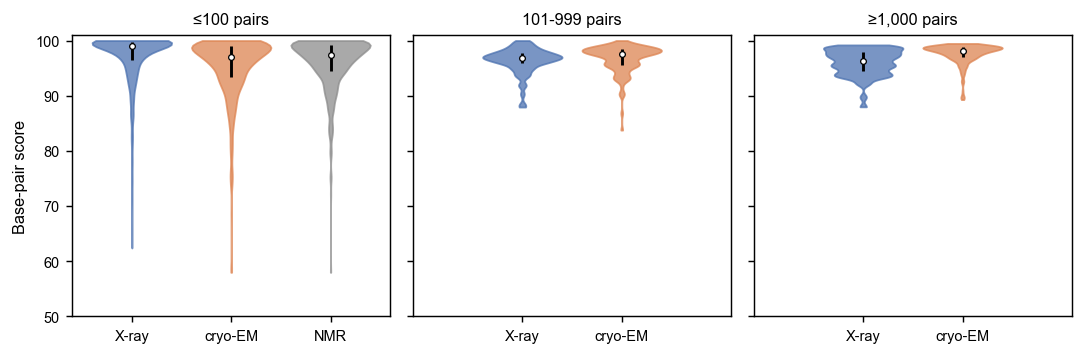

In [3]:
def draw_a(axes):
    method_row(axes, "pairs_score", "Base-pair score")


fig, axes = plt.subplots(1, len(SIZE_BINS), figsize=(8.4, 2.8))
draw_a(axes)
fig.tight_layout()
save(fig, "figures/supplemental/figS7_A_scores_by_method.png")
plt.show()


## Panel B
Backbone-suiteness distributions for X-ray, cryo-EM and NMR structures, by structure size


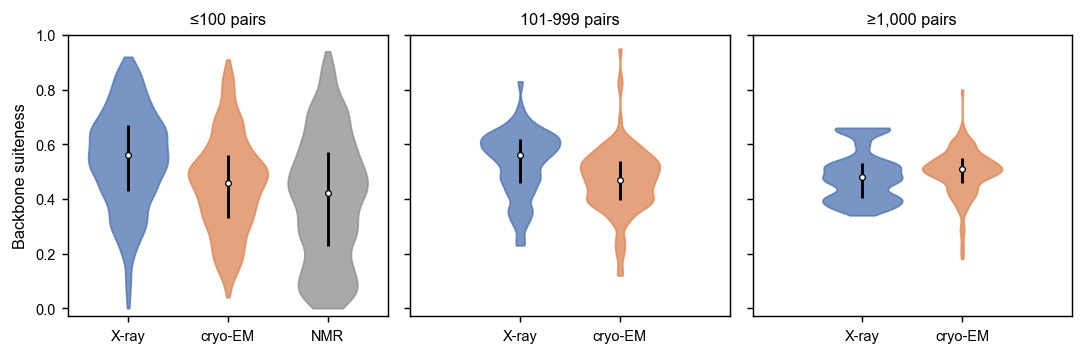

In [4]:
def draw_b(axes):
    method_row(axes, "backbone_suiteness", "Backbone suiteness")


fig, axes = plt.subplots(1, len(SIZE_BINS), figsize=(8.4, 2.8))
draw_b(axes)
fig.tight_layout()
save(fig, "figures/supplemental/figS7_B_suiteness_by_method.png")
plt.show()


## Combined figure


text scaled x1.57: 7 pt prints at 7.1 pt at page width


axis titles print at 8.5 pt and panel letters at 12.0 pt (10.44 in saved, shown at 6.73 in)


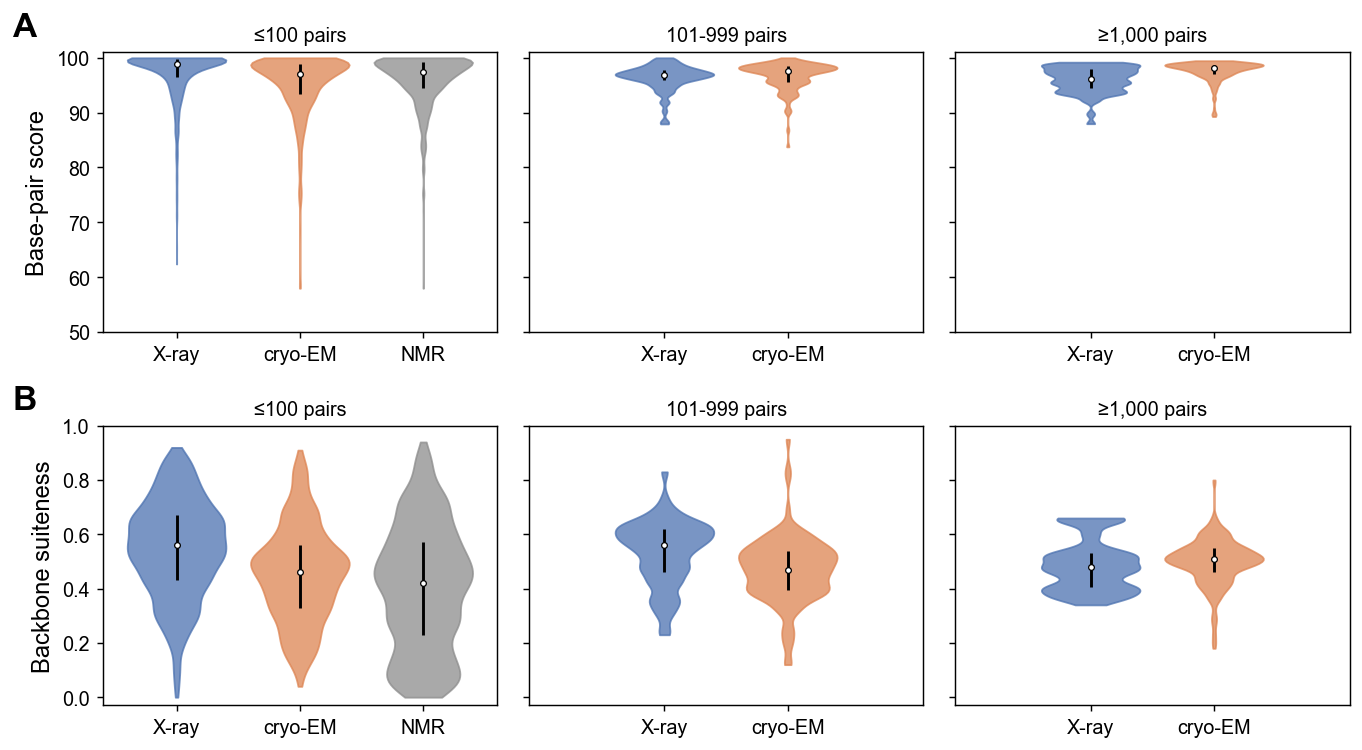

In [5]:



fig = plt.figure(figsize=(10.6, 5.91))
gs = fig.add_gridspec(2, len(SIZE_BINS), wspace=0.08, hspace=0.335,
                      left=0.08, right=0.985, top=0.93, bottom=0.08)
axes_a = [fig.add_subplot(gs[0, i]) for i in range(len(SIZE_BINS))]
axes_b = [fig.add_subplot(gs[1, i]) for i in range(len(SIZE_BINS))]
draw_a(axes_a); draw_b(axes_b)
for ax, s in ((axes_a[0], "A"), (axes_b[0], "B")):
    letter(fig, ax, s, dx=-0.065)
import matplotlib.text as mtext
for _t in fig.findobj(mtext.Text):
    if _t in fig.texts and _t.get_fontweight() in ("bold", 700) and len(_t.get_text().strip()) <= 2:
        _t.set_fontsize(12)
    else:
        _t.set_fontsize(7)
enlarge_axis_labels(fig)
for _ax in fig.axes:
    _ax.xaxis.label.set_fontsize(7)
    _ax.yaxis.label.set_fontsize(7)
import matplotlib.text as _mtext
def _print_scale(fig, page_in=6.73, pad=0.08):
    fig.canvas.draw()
    bb = fig.get_tightbbox(fig.canvas.get_renderer())
    return max(1.0, (bb.width + 2 * pad) / page_in)
fig.canvas.draw()
_texts = [t for t in fig.findobj(_mtext.Text) if t.get_text().strip()]
_base = {t: t.get_fontsize() for t in _texts}
_s = 1.0
for _ in range(6):
    _need = _print_scale(fig)
    if _s >= _need - 1e-3:
        break
    _s = _need * 1.01
    for _t in _texts:
        _t.set_fontsize(_base[_t] * _s)
print(f"text scaled x{_s:.2f}: 7 pt prints at {7 * _s / _print_scale(fig):.1f} pt "
      f"at page width")
def _set_print_sizes(fig, axis_pt=8.5, letter_pt=12.0, page_in=6.73, pad=0.08):
    letters = [t for t in fig.texts if t.get_text().strip().isalpha()
               and t.get_text().strip().isupper() and len(t.get_text().strip()) <= 2
               and t.get_fontweight() in ("bold", 700)]
    for _ in range(8):
        fig.canvas.draw()
        bb = fig.get_tightbbox(fig.canvas.get_renderer())
        shrink = max(1.0, (bb.width + 2 * pad) / page_in)
        for ax in fig.axes:
            for lab in (ax.xaxis.label, ax.yaxis.label):
                if lab.get_text().strip():
                    lab.set_fontsize(axis_pt * shrink)
        for t in letters:
            t.set_fontsize(letter_pt * shrink)
    print(f"axis titles print at {axis_pt} pt and panel letters at {letter_pt} pt "
          f"({bb.width + 2 * pad:.2f} in saved, shown at {min(page_in, bb.width + 2 * pad):.2f} in)")


_set_print_sizes(fig)

save(fig, "figures/supplemental/figS7.png")
plt.show()
